In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler

In [4]:
df_low_pop = pd.read_csv('low_popularity_spotify_data.csv')
df_high_pop = pd.read_csv('high_popularity_spotify_data.csv')

In [5]:
df_low_pop.head()

,time_signature,track_popularity,speechiness,danceability,playlist_name,track_artist,duration_ms,energy,playlist_genre,playlist_subgenre,...,track_album_id,playlist_id,track_id,valence,key,tempo,loudness,acousticness,liveness,track_album_name
0,4.0,23,0.0393,0.636,Rock Classics,Creedence Clearwater Revival,138053.0,0.746,rock,classic,...,4A8gFwqd9jTtnsNwUu3OQx,37i9dQZF1DWXRqgorJj26U,5e6x5YRnMJIKvYpZxLqdpH,0.432,0.0,132.310,-3.785,0.0648,0.1730,The Long Road Home - The Ultimate John Fogerty...
1,4.0,53,0.0317,0.572,Rock Classics,Van Halen,241600.0,0.835,rock,classic,...,2c965LEDRNrXXCeBOAAwns,37i9dQZF1DWXRqgorJj26U,5FqYA8KfiwsQvyBI4IamnY,0.795,0.0,129.981,-6.219,0.1710,0.0702,The Collection
2,4.0,55,0.0454,0.591,Rock Classics,Stevie Nicks,329413.0,0.804,rock,classic,...,3S404OgKoVQSJ3xXrDVlp8,37i9dQZF1DWXRqgorJj26U,5LNiqEqpDc8TuqPy79kDBu,0.658,0.0,111.457,-7.299,0.3270,0.0818,Bella Donna (Deluxe Edition)
3,4.0,64,0.1010,0.443,Jazz Classics,"Ella Fitzgerald, Louis Armstrong",185160.0,0.104,jazz,classic,...,1y5KGkUKO0NG32MhIIagCA,37i9dQZF1DXbITWG1ZJKYt,78MI7mu1LV1k4IA2HzKmHe,0.394,0.0,76.474,-17.042,0.9130,0.1910,"Love, Ella"
4,4.0,62,0.0298,0.685,Jazz Classics,Galt MacDermot,205720.0,0.472,jazz,classic,...,6f4b9wVTkKAf096k4XG6x5,37i9dQZF1DXbITWG1ZJKYt,6MN6yRVriszuyAVlyF8ndB,0.475,9.0,80.487,-9.691,0.7850,0.2240,Shapes of Rhythm/Woman Is Sweeter


In [6]:
df_high_pop.head()

,energy,tempo,danceability,playlist_genre,loudness,liveness,valence,track_artist,time_signature,speechiness,...,instrumentalness,track_album_id,mode,key,duration_ms,acousticness,id,playlist_subgenre,type,playlist_id
0,0.592,157.969,0.521,pop,-7.777,0.122,0.535,"Lady Gaga, Bruno Mars",3,0.0304,...,0.0000,10FLjwfpbxLmW8c25Xyc2N,0,6,251668,0.3080,2plbrEY59IikOBgBGLjaoe,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
1,0.507,104.978,0.747,pop,-10.171,0.117,0.438,Billie Eilish,4,0.0358,...,0.0608,7aJuG4TFXa2hmE4z1yxc3n,1,2,210373,0.2000,6dOtVTDdiauQNBQEDOtlAB,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
2,0.808,108.548,0.554,pop,-4.169,0.159,0.372,Gracie Abrams,4,0.0368,...,0.0000,0hBRqPYPXhr1RkTDG3n4Mk,1,1,166300,0.2140,7ne4VBA60CxGM75vw0EYad,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
3,0.910,112.966,0.670,pop,-4.070,0.304,0.786,Sabrina Carpenter,4,0.0634,...,0.0000,4B4Elma4nNDUyl6D5PvQkj,0,0,157280,0.0939,1d7Ptw3qYcfpdLNL5REhtJ,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M
4,0.783,149.027,0.777,pop,-4.477,0.355,0.939,"ROSÉ, Bruno Mars",4,0.2600,...,0.0000,2IYQwwgxgOIn7t3iF6ufFD,0,0,169917,0.0283,5vNRhkKd0yEAg8suGBpjeY,mainstream,audio_features,37i9dQZF1DXcBWIGoYBM5M


In [7]:
music_df = pd.concat([df_low_pop, df_high_pop], ignore_index=True)
music_df

,time_signature,track_popularity,speechiness,danceability,playlist_name,track_artist,duration_ms,energy,playlist_genre,playlist_subgenre,...,track_album_id,playlist_id,track_id,valence,key,tempo,loudness,acousticness,liveness,track_album_name
0,4.0,23,0.0393,0.636,Rock Classics,Creedence Clearwater Revival,138053.0,0.746,rock,classic,...,4A8gFwqd9jTtnsNwUu3OQx,37i9dQZF1DWXRqgorJj26U,5e6x5YRnMJIKvYpZxLqdpH,0.432,0.0,132.310,-3.785,0.0648,0.1730,The Long Road Home - The Ultimate John Fogerty...
1,4.0,53,0.0317,0.572,Rock Classics,Van Halen,241600.0,0.835,rock,classic,...,2c965LEDRNrXXCeBOAAwns,37i9dQZF1DWXRqgorJj26U,5FqYA8KfiwsQvyBI4IamnY,0.795,0.0,129.981,-6.219,0.1710,0.0702,The Collection
2,4.0,55,0.0454,0.591,Rock Classics,Stevie Nicks,329413.0,0.804,rock,classic,...,3S404OgKoVQSJ3xXrDVlp8,37i9dQZF1DWXRqgorJj26U,5LNiqEqpDc8TuqPy79kDBu,0.658,0.0,111.457,-7.299,0.3270,0.0818,Bella Donna (Deluxe Edition)
3,4.0,64,0.1010,0.443,Jazz Classics,"Ella Fitzgerald, Louis Armstrong",185160.0,0.104,jazz,classic,...,1y5KGkUKO0NG32MhIIagCA,37i9dQZF1DXbITWG1ZJKYt,78MI7mu1LV1k4IA2HzKmHe,0.394,0.0,76.474,-17.042,0.9130,0.1910,"Love, Ella"
4,4.0,62,0.0298,0.685,Jazz Classics,Galt MacDermot,205720.0,0.472,jazz,classic,...,6f4b9wVTkKAf096k4XG6x5,37i9dQZF1DXbITWG1ZJKYt,6MN6yRVriszuyAVlyF8ndB,0.475,9.0,80.487,-9.691,0.7850,0.2240,Shapes of Rhythm/Woman Is Sweeter
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4826,5.0,76,0.0678,0.573,Afro-Latin Party,Libianca,184791.0,0.422,latin,afro-latin,...,5Hmh6N8oisrcuZKa8EY5dn,0oU30cCr8klmMsuOKHDLkh,26b3oVLrRUaaybJulow9kz,0.693,10.0,124.357,-7.621,0.5510,0.1020,People
4827,4.0,74,0.0941,0.711,Afro-Latin Party,Omah Lay,183057.0,0.725,latin,afro-latin,...,5NLjxx8nRy9ooUmgpOvfem,0oU30cCr8klmMsuOKHDLkh,1wADwLSkYhrSmy4vdy6BRn,0.530,3.0,105.016,-8.315,0.4240,0.1100,Boy Alone
4828,4.0,69,0.0929,0.724,Afro-Latin Party,"Davido, FAVE",194040.0,0.809,latin,afro-latin,...,6lI21W76LD0S3vC55GrfSS,0oU30cCr8klmMsuOKHDLkh,7vKXc90NT5WBm3UTT4iTVG,0.606,6.0,99.005,-5.022,0.1820,0.0765,Timeless
4829,4.0,82,0.3400,0.463,Afro-Latin Party,"Future, Drake, Tems",189893.0,0.642,latin,afro-latin,...,6tE9Dnp2zInFij4jKssysL,0oU30cCr8klmMsuOKHDLkh,59nOXPmaKlBfGMDeOVGrIK,0.339,1.0,83.389,-4.474,0.3140,0.0686,I NEVER LIKED YOU


In [8]:
duplicates = music_df.duplicated().sum()

if duplicates > 0:
  music_df = music_df.drop_duplicates().copy()
else:
  print('No duplicates found')

In [9]:
pop_stats = music_df['track_popularity'].describe()
pop_stats

,track_popularity
count,4788.000000
mean,54.642231
std,19.877514
min,11.000000
25%,41.000000
50%,55.000000
75%,72.000000
max,100.000000


In [10]:
print("Track Popularity Balance: ")
print(f"  Songs with popularity < 50: {(music_df['track_popularity'] < 50).sum():,} ({(music_df['track_popularity'] < 50).sum()/len(music_df)*100:.1f}%)")
print(f"  Songs with popularity ≥ 50: {(music_df['track_popularity'] >= 50).sum():,} ({(music_df['track_popularity'] >= 50).sum()/len(music_df)*100:.1f}%)")

Track Popularity Balance: 
  Songs with popularity < 50: 1,919 (40.1%)
  Songs with popularity ≥ 50: 2,869 (59.9%)


In [11]:
print(f"Average track popularity: {music_df['track_popularity'].mean():.1f}")

Average track popularity: 54.6


Checking if any songs are mussing track popularity metrics.

In [12]:
print(music_df['track_popularity'].isnull().sum())

0


[Text(1, 0, 'All Songs')]

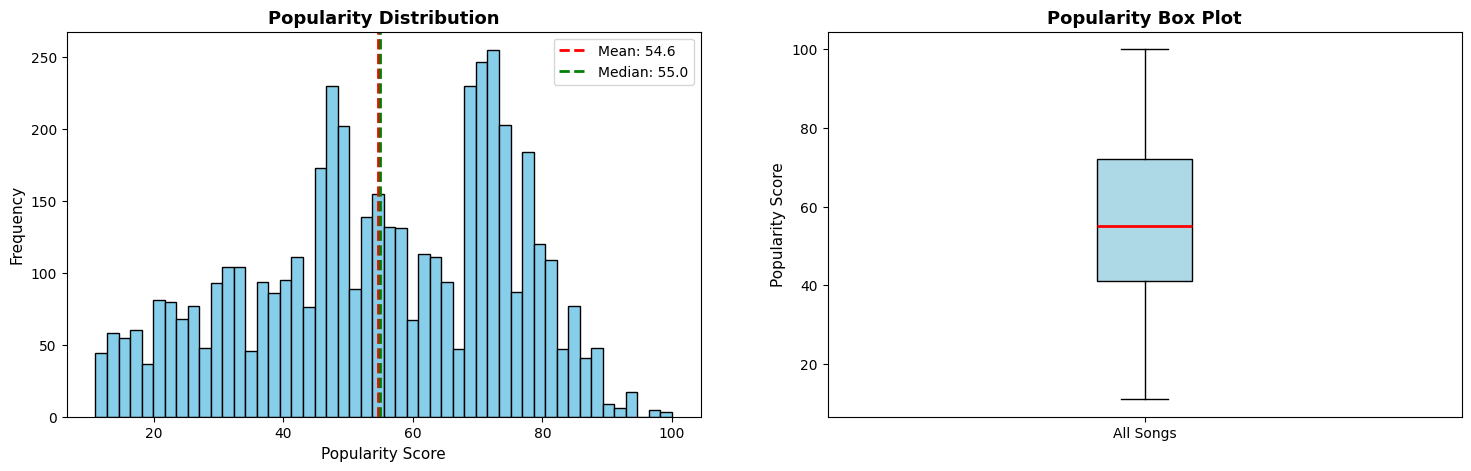

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

axes[0].hist(music_df['track_popularity'], bins=50, color='skyblue', edgecolor='black')
axes[0].axvline(music_df['track_popularity'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {music_df["track_popularity"].mean():.1f}')
axes[0].axvline(music_df['track_popularity'].median(), color='green', linestyle='--', linewidth=2, label=f'Median: {music_df["track_popularity"].median():.1f}')
axes[0].set_xlabel('Popularity Score', fontsize=11)
axes[0].set_ylabel('Frequency', fontsize=11)
axes[0].set_title('Popularity Distribution', fontsize=13, fontweight='bold')
axes[0].legend()

axes[1].boxplot(music_df['track_popularity'], vert=True, patch_artist=True,
                boxprops=dict(facecolor='lightblue', color='black'),
                medianprops=dict(color='red', linewidth=2))
axes[1].set_ylabel('Popularity Score', fontsize=11)
axes[1].set_title('Popularity Box Plot', fontsize=13, fontweight='bold')
axes[1].set_xticklabels(['All Songs'])





In [14]:
music_df['popularity_category'] = pd.cut(music_df['track_popularity'],
                                          bins=[0, 40, 60, 80, 100],
                                          labels=['Low', 'Medium', 'High', 'Very High'])

print("\nPopularity Categories:")
print(music_df['popularity_category'].value_counts().sort_index())


Popularity Categories:
popularity_category
Low          1180
Medium       1555
High         1691
Very High     362
Name: count, dtype: int64


In [15]:
low_pop_songs = music_df[music_df['track_popularity'] < 50]
high_pop_songs = music_df[music_df['track_popularity'] >= 50]

features = ['acousticness', 'danceability', 'duration_ms', 'energy', 'instrumentalness', 'key', 'liveness', 'loudness', 'mode', 'speechiness', 'tempo', 'valence']
features_stats = pd.DataFrame({
    'Feature': features,
    'Low Pop Mean': [low_pop_songs[f].mean() for f in features],
    'High Pop Mean': [high_pop_songs[f].mean() for f in features],
    'Difference': [high_pop_songs[f].mean() - low_pop_songs[f].mean() for f in features]
})

In [16]:
features_stats['Difference %'] = (features_stats['Difference'] / features_stats['Low Pop Mean'] * 100).round(1)

print("\nMean Feature Values Comparison:")
print(features_stats.to_string(index=False))

print("PHASE 2: FEATURE-POPULARITY CORRELATION ANALYSIS")

audio_features = ['danceability', 'energy', 'loudness', 'speechiness',
                  'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

correlations = music_df[audio_features + ['track_popularity']].corr()['track_popularity'].sort_values(ascending=False)
print("\nCorrelation with Popularity:")
print(correlations[1:])


Mean Feature Values Comparison:
         Feature  Low Pop Mean  High Pop Mean  Difference  Difference %
    acousticness      0.426111       0.285830   -0.140281         -32.9
    danceability      0.592667       0.641334    0.048668           8.2
     duration_ms 202007.778009  209001.475593 6993.697583           3.5
          energy      0.525433       0.626280    0.100847          19.2
instrumentalness      0.321605       0.122643   -0.198962         -61.9
             key      5.154247       5.279986    0.125739           2.4
        liveness      0.161826       0.171716    0.009890           6.1
        loudness    -11.219788      -8.014748    3.205040         -28.6
            mode      0.558624       0.565900    0.007275           1.3
     speechiness      0.098013       0.103424    0.005412           5.5
           tempo    115.963643     119.773960    3.810317           3.3
         valence      0.452211       0.500948    0.048737          10.8
PHASE 2: FEATURE-POPULARITY COR

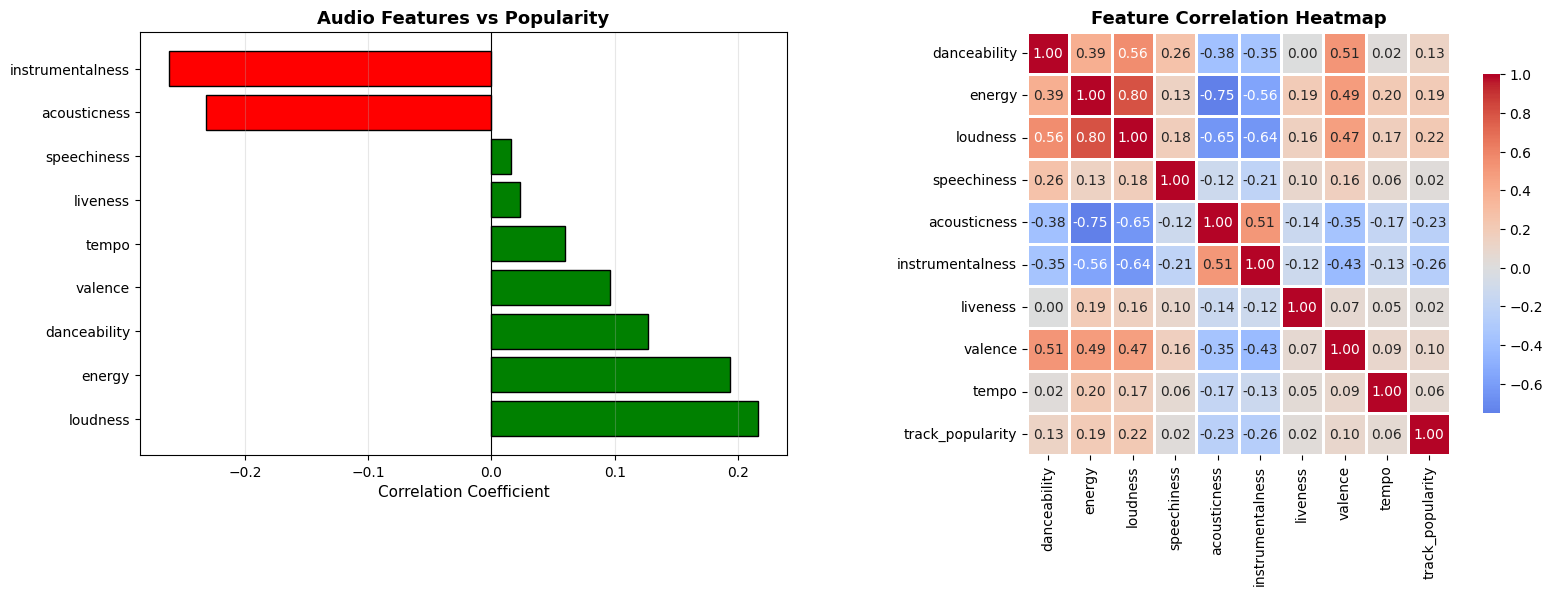

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors = ['green' if x > 0 else 'red' for x in correlations[1:].values]
axes[0].barh(range(len(correlations[1:])), correlations[1:].values, color=colors, edgecolor='black')
axes[0].set_yticks(range(len(correlations[1:])))
axes[0].set_yticklabels(correlations[1:].index)
axes[0].set_xlabel('Correlation Coefficient', fontsize=11)
axes[0].set_title('Audio Features vs Popularity', fontsize=13, fontweight='bold')
axes[0].axvline(x=0, color='black', linestyle='-', linewidth=0.8)
axes[0].grid(axis='x', alpha=0.3)

corr_matrix = music_df[audio_features + ['track_popularity']].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8}, ax=axes[1])
axes[1].set_title('Feature Correlation Heatmap', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

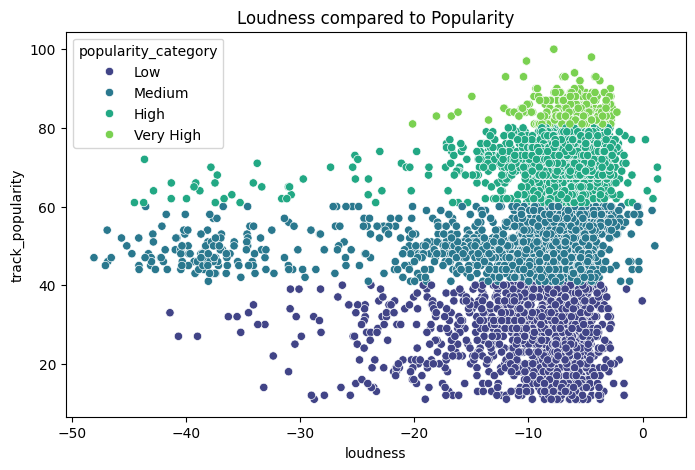

In [18]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=music_df, x='loudness', y='track_popularity', hue='popularity_category', palette='viridis')
plt.title("Loudness compared to Popularity")
plt.show()

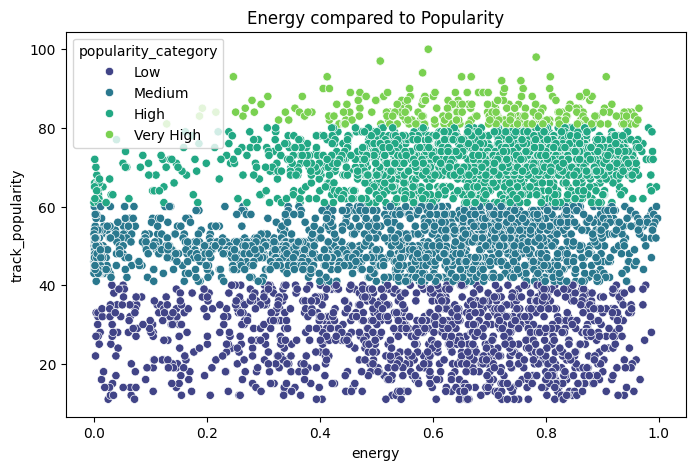

In [19]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=music_df, x='energy', y='track_popularity', hue='popularity_category', palette='viridis')
plt.title("Energy compared to Popularity")
plt.show()

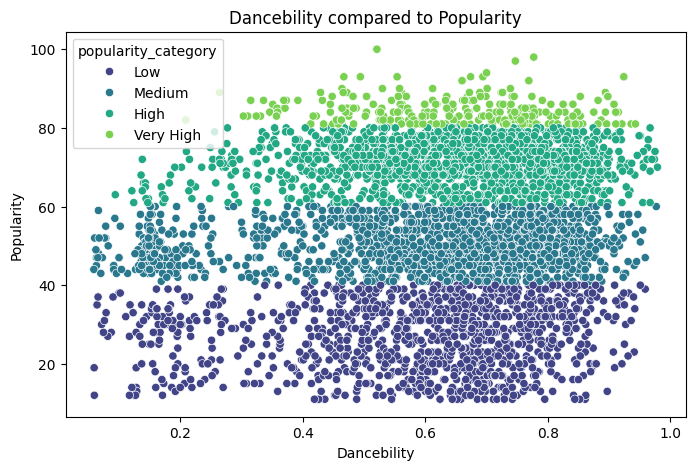

In [20]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=music_df, x='danceability', y='track_popularity', hue='popularity_category', palette='viridis')
plt.title("Dancebility compared to Popularity")
plt.xlabel("Dancebility")
plt.ylabel("Popularity")
plt.show()

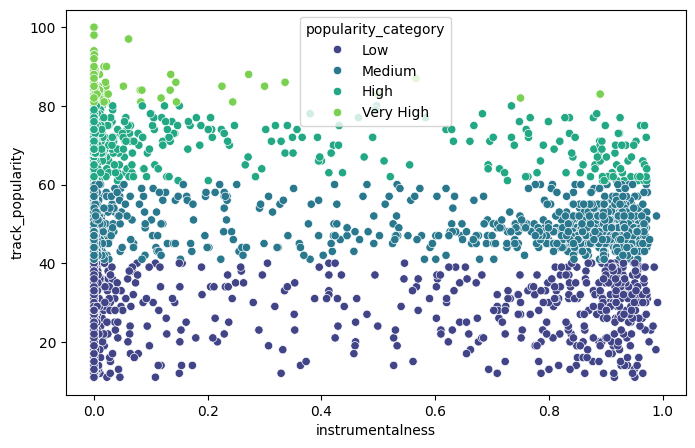

In [21]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=music_df, x='instrumentalness', y='track_popularity', hue='popularity_category', palette='viridis')
plt.show()

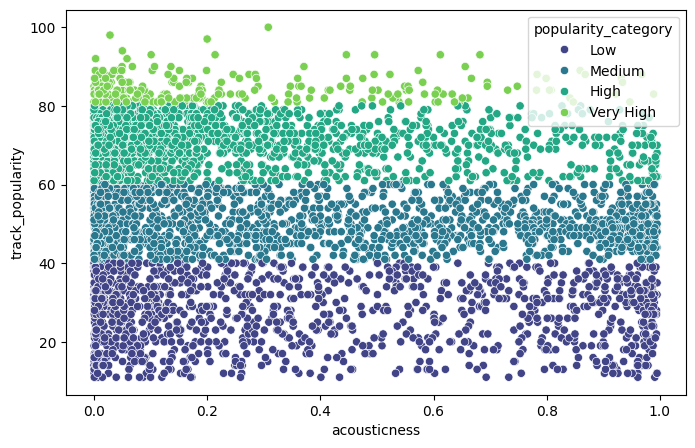

In [22]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=music_df, x='acousticness', y='track_popularity', hue='popularity_category', palette='viridis')
plt.show()

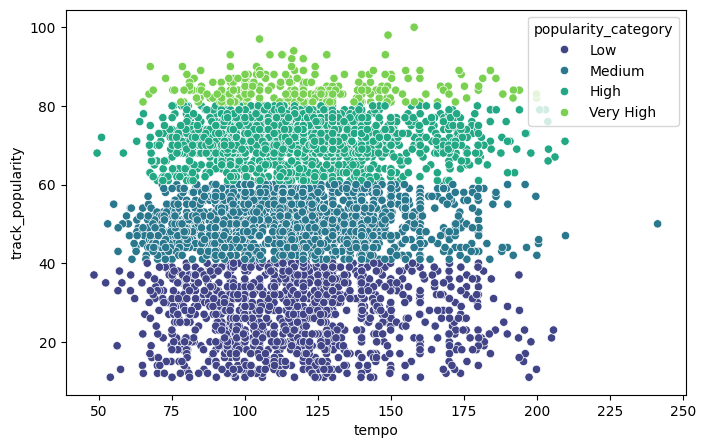

In [23]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=music_df, x='tempo', y='track_popularity', hue='popularity_category', palette='viridis')
plt.show()

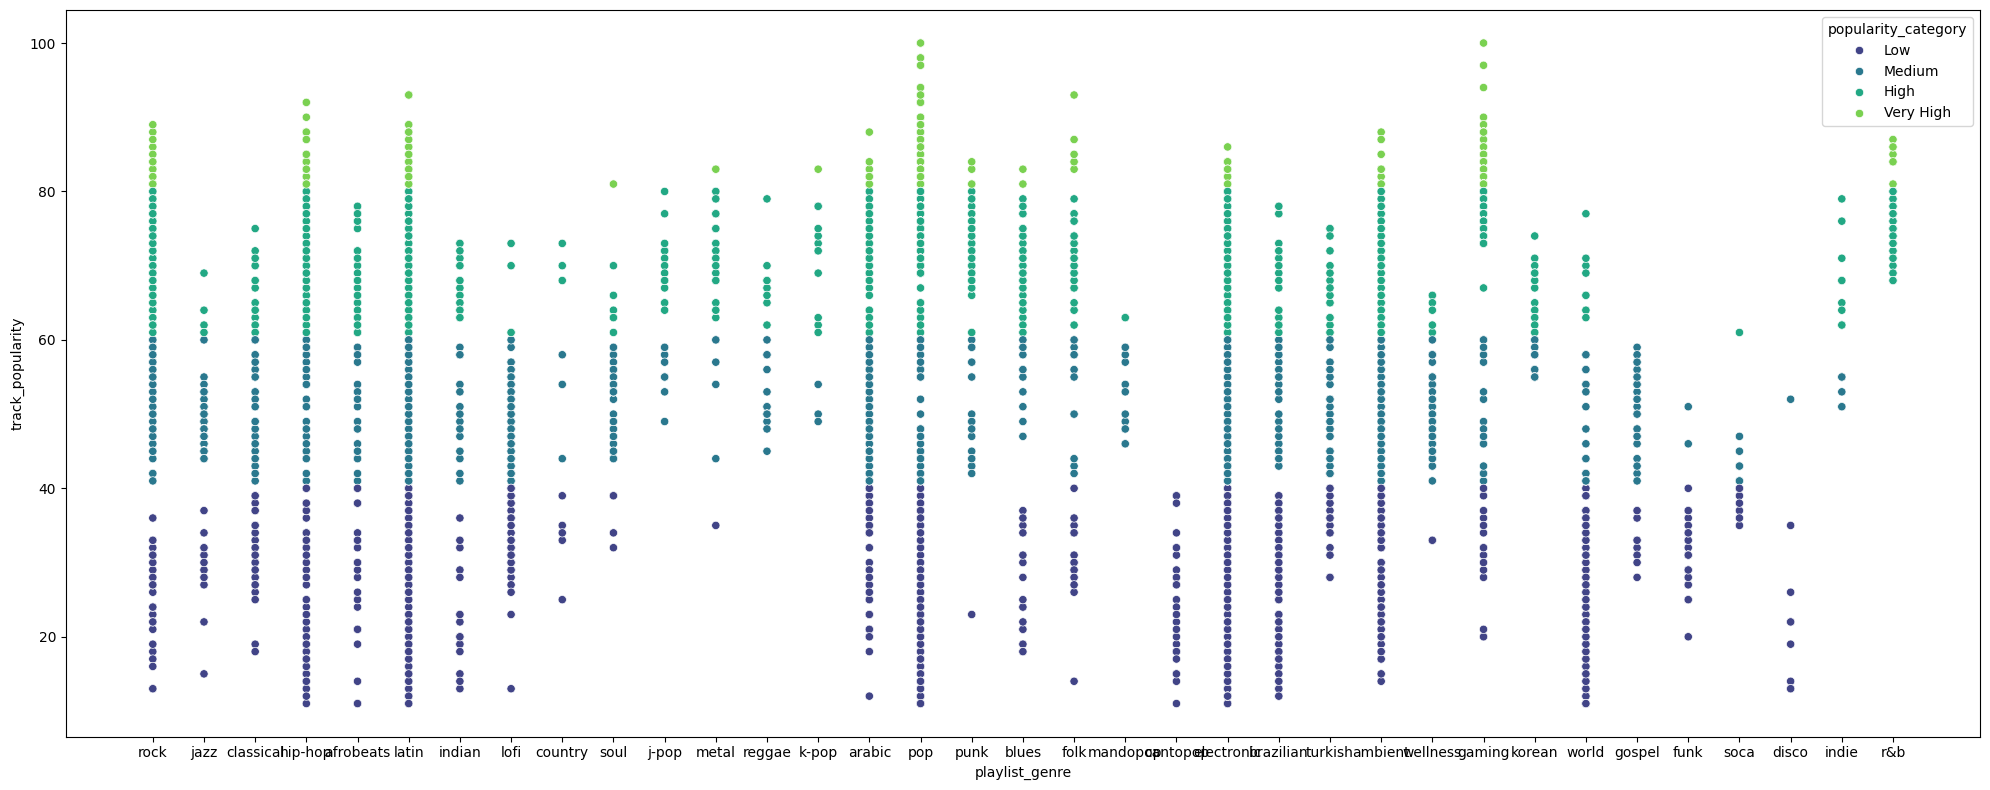

In [24]:
plt.figure(figsize=(20, 8))
sns.scatterplot(data=music_df, x='playlist_genre', y='track_popularity', hue='popularity_category', palette='viridis')
plt.tight_layout()
plt.show()

In [25]:
music_df['energy_danceability'] = music_df['energy'] * music_df['danceability']
music_df['loudness_energy'] = music_df['loudness'] * music_df['energy']
music_df['valence_danceability'] = music_df['valence'] * music_df['danceability']
music_df['acoustic_energy_ratio'] = music_df['acousticness'] / (music_df['energy'] + 0.001)
music_df['tempo_normalized'] = music_df['tempo'] / 200  # Normalize tempo
music_df['catchiness'] = (music_df['danceability'] + music_df['valence'] + music_df['energy']) / 3
music_df['party_score'] = music_df['danceability'] * music_df['energy'] * music_df['loudness']

music_df['duration_min'] = music_df['duration_ms'] / 60000

if 'explicit' in music_df.columns:
    music_df['is_explicit'] = music_df['explicit'].astype(int)

print("\nEngineered Features Created:")
print("- energy_danceability: energy × danceability")
print("- loudness_energy: loudness × energy")
print("- valence_danceability: valence × danceability")
print("- acoustic_energy_ratio: acousticness / energy")
print("- tempo_normalized: tempo / 200")
print("- catchiness: mean(danceability, valence, energy)")
print("- party_score: danceability × energy × loudness")
print("- duration_min: duration in minutes")

engineered_features = ['energy_danceability', 'loudness_energy', 'valence_danceability',
                      'acoustic_energy_ratio', 'catchiness', 'party_score']
new_correlations = music_df[engineered_features + ['track_popularity']].corr()['track_popularity'].sort_values(ascending=False)

print("\nNew Features Correlation with Popularity:")
print(new_correlations[1:])


Engineered Features Created:
- energy_danceability: energy × danceability
- loudness_energy: loudness × energy
- valence_danceability: valence × danceability
- acoustic_energy_ratio: acousticness / energy
- tempo_normalized: tempo / 200
- catchiness: mean(danceability, valence, energy)
- party_score: danceability × energy × loudness
- duration_min: duration in minutes

New Features Correlation with Popularity:
energy_danceability      0.181194
catchiness               0.172744
valence_danceability     0.097229
loudness_energy          0.078756
party_score              0.019656
acoustic_energy_ratio   -0.046297
Name: track_popularity, dtype: float64


In [26]:
feature_list = audio_features + engineered_features + ['duration_min']
if 'is_explicit' in music_df.columns:
    feature_list.append('is_explicit')

music_df_clean = music_df[feature_list + ['track_popularity']].dropna()
print(f"\nRows after cleaning: {len(music_df_clean):,} (removed {len(music_df) - len(music_df_clean):,})")

X = music_df_clean[feature_list]
y = music_df_clean['track_popularity']

print(f"\nFeatures used for modeling: {len(feature_list)}")
print(f"Target variable range: [{y.min():.1f}, {y.max():.1f}]")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)




Rows after cleaning: 4,787 (removed 1)

Features used for modeling: 16
Target variable range: [11.0, 100.0]


In [27]:
models_results = {}

def evaluate_model(name, model, X_train, y_train, X_test, y_test):

    model.fit(X_train, y_train)

    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    train_r2 = r2_score(y_train, y_pred_train)
    test_r2 = r2_score(y_test, y_pred_test)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
    test_mae = mean_absolute_error(y_test, y_pred_test)

    cv_scores = cross_val_score(model, X_train, y_train, cv=5,
                                scoring='r2', n_jobs=-1)

    return {
        'model': model,
        'train_r2': train_r2,
        'test_r2': test_r2,
        'test_rmse': test_rmse,
        'test_mae': test_mae,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std(),
        'predictions': y_pred_test
    }


Linear Regression:

In [28]:
lr = LinearRegression()
models_results['Linear Regression'] = evaluate_model('Linear Regression', lr,
                                                      X_train_scaled, y_train,
                                                      X_test_scaled, y_test)
print(f"  R² Score: {models_results['Linear Regression']['test_r2']:.4f}")
print(f"  RMSE: {models_results['Linear Regression']['test_rmse']:.4f}")


  R² Score: 0.1135
  RMSE: 18.9448


Ridge Regression:

In [29]:
ridge_params = {'alpha': [0.001, 0.01, 0.1, 1, 10, 100]}
ridge_grid = GridSearchCV(Ridge(), ridge_params, cv=5, scoring='r2', n_jobs=-1)
ridge_grid.fit(X_train_scaled, y_train)
ridge_best = ridge_grid.best_estimator_

models_results['Ridge Regression'] = evaluate_model('Ridge Regression', ridge_best,
                                                     X_train_scaled, y_train,
                                                     X_test_scaled, y_test)
print(f"  Best alpha: {ridge_grid.best_params_['alpha']}")
print(f"  R² Score: {models_results['Ridge Regression']['test_r2']:.4f}")
print(f"  RMSE: {models_results['Ridge Regression']['test_rmse']:.4f}")


  Best alpha: 10
  R² Score: 0.1135
  RMSE: 18.9444


Decision Tree

In [30]:
dt_params = {
    'max_depth': [5, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
dt_grid = GridSearchCV(DecisionTreeRegressor(random_state=42), dt_params,
                       cv=5, scoring='r2', n_jobs=-1)
dt_grid.fit(X_train_scaled, y_train)
dt_best = dt_grid.best_estimator_

models_results['Decision Tree'] = evaluate_model('Decision Tree', dt_best,
                                                  X_train_scaled, y_train,
                                                  X_test_scaled, y_test)

print(f"  Best params: {dt_grid.best_params_}")
print(f"  R² Score: {models_results['Decision Tree']['test_r2']:.4f}")
print(f"  RMSE: {models_results['Decision Tree']['test_rmse']:.4f}")

  Best params: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 5}
  R² Score: 0.0880
  RMSE: 19.2153


Random Forest

In [31]:
rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}
rf_grid = GridSearchCV(RandomForestRegressor(random_state=42), rf_params,
                       cv=5, scoring='r2', n_jobs=-1)
rf_grid.fit(X_train_scaled, y_train)
rf_best = rf_grid.best_estimator_

models_results['Random Forest'] = evaluate_model('Random Forest', rf_best,
                                                  X_train_scaled, y_train,
                                                  X_test_scaled, y_test)
print(f"  Best params: {rf_grid.best_params_}")
print(f"  R² Score: {models_results['Random Forest']['test_r2']:.4f}")
print(f"  RMSE: {models_results['Random Forest']['test_rmse']:.4f}")

  Best params: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
  R² Score: 0.2438
  RMSE: 17.4970


Gradient Boosting

In [32]:
gb_params = {
    'n_estimators': [100, 200],
    'learning_rate': [0.01, 0.1],
    'max_depth': [3, 5, 7],
    'subsample': [0.8, 1.0]
}
gb_grid = GridSearchCV(GradientBoostingRegressor(random_state=42), gb_params,
                       cv=5, scoring='r2', n_jobs=-1)
gb_grid.fit(X_train_scaled, y_train)
gb_best = gb_grid.best_estimator_

models_results['Gradient Boosting'] = evaluate_model('Gradient Boosting', gb_best,
                                                      X_train_scaled, y_train,
                                                      X_test_scaled, y_test)

print(f"  Best params: {gb_grid.best_params_}")
print(f"  R² Score: {models_results['Gradient Boosting']['test_r2']:.4f}")
print(f"  RMSE: {models_results['Gradient Boosting']['test_rmse']:.4f}")

  Best params: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 100, 'subsample': 0.8}
  R² Score: 0.1970
  RMSE: 18.0306


Model Comparison


            Model  Train R²  Test R²      RMSE       MAE  CV Mean   CV Std
Linear Regression  0.122080 0.113483 18.944784 15.431911 0.113685 0.013015
 Ridge Regression  0.121969 0.113516 18.944425 15.443382 0.113815 0.012685
    Decision Tree  0.196681 0.087981 19.215339 15.485639 0.087941 0.015688
    Random Forest  0.892534 0.243807 17.496951 13.723411 0.217292 0.035859
Gradient Boosting  0.832778 0.196975 18.030613 14.004262 0.178168 0.035431


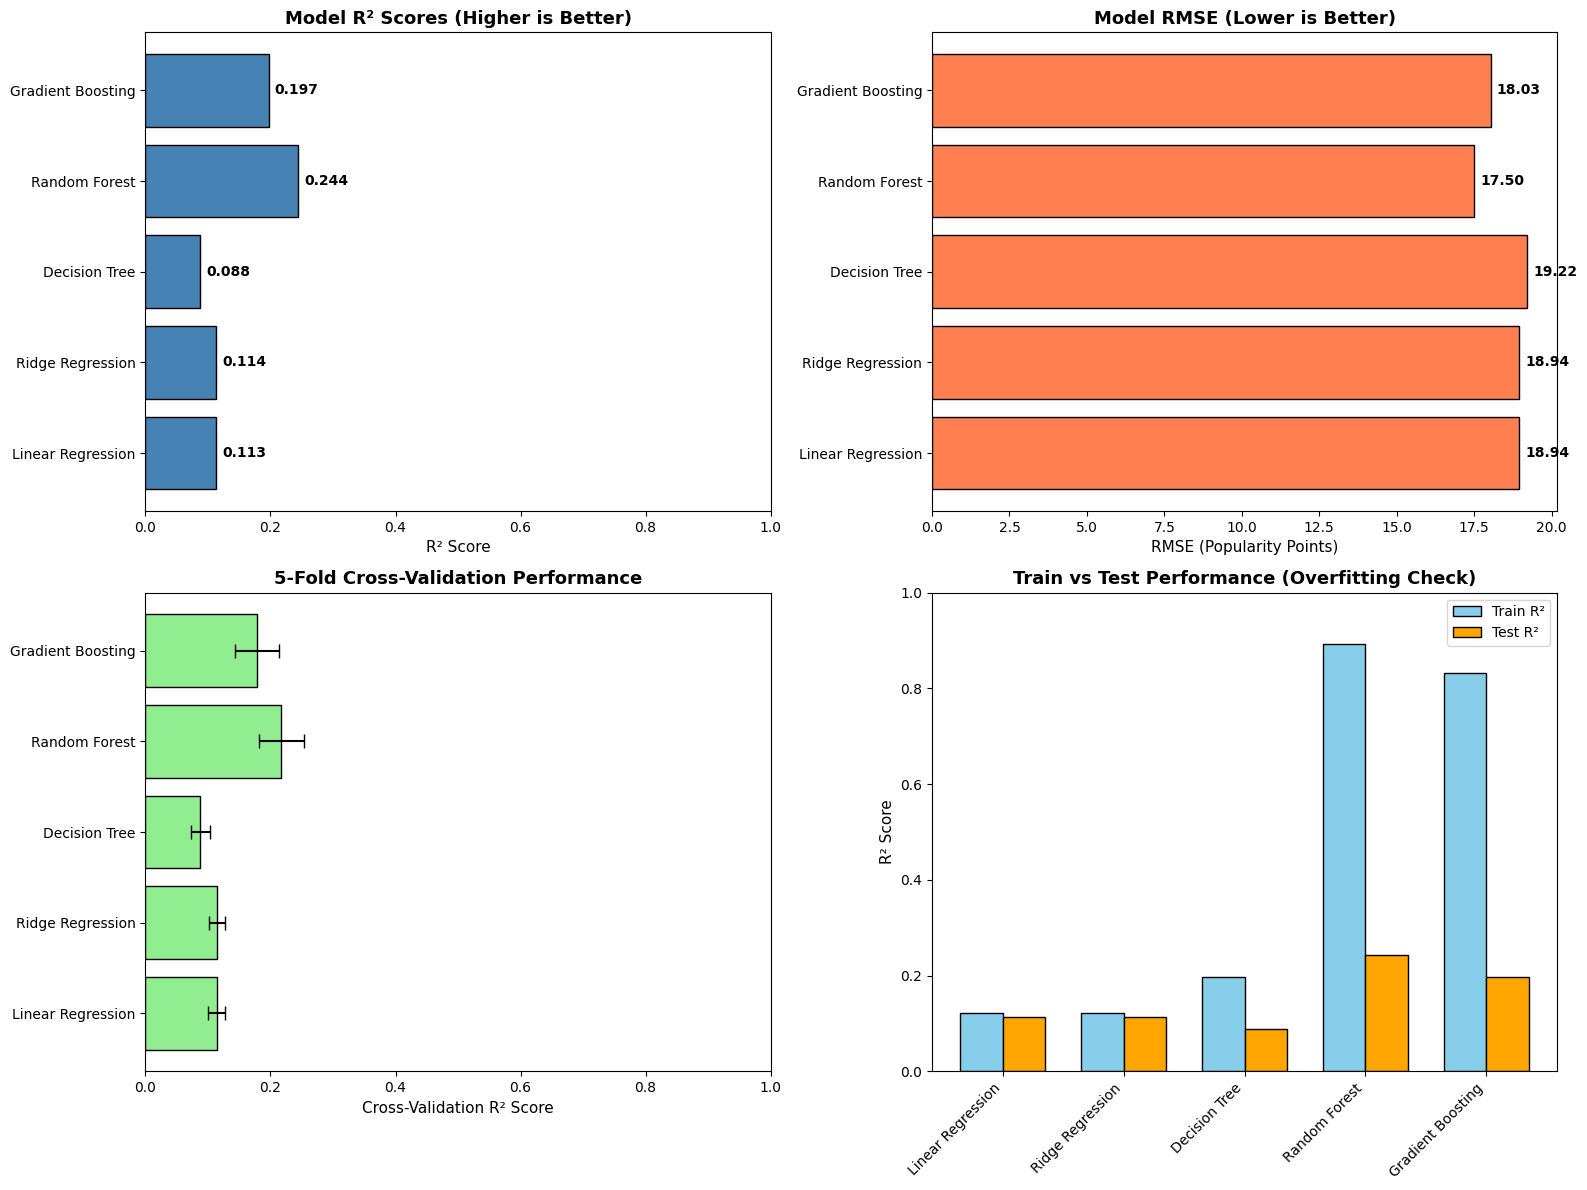

In [33]:
comparison_df = pd.DataFrame({
    'Model': list(models_results.keys()),
    'Train R²': [r['train_r2'] for r in models_results.values()],
    'Test R²': [r['test_r2'] for r in models_results.values()],
    'RMSE': [r['test_rmse'] for r in models_results.values()],
    'MAE': [r['test_mae'] for r in models_results.values()],
    'CV Mean': [r['cv_mean'] for r in models_results.values()],
    'CV Std': [r['cv_std'] for r in models_results.values()],
})

print("\n" + comparison_df.to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

axes[0, 0].barh(comparison_df['Model'], comparison_df['Test R²'], color='steelblue', edgecolor='black')
axes[0, 0].set_xlabel('R² Score', fontsize=11)
axes[0, 0].set_title('Model R² Scores (Higher is Better)', fontsize=13, fontweight='bold')
axes[0, 0].set_xlim([0, 1])
for i, v in enumerate(comparison_df['Test R²']):
    axes[0, 0].text(v + 0.01, i, f'{v:.3f}', va='center', fontweight='bold')

axes[0, 1].barh(comparison_df['Model'], comparison_df['RMSE'], color='coral', edgecolor='black')
axes[0, 1].set_xlabel('RMSE (Popularity Points)', fontsize=11)
axes[0, 1].set_title('Model RMSE (Lower is Better)', fontsize=13, fontweight='bold')
for i, v in enumerate(comparison_df['RMSE']):
    axes[0, 1].text(v + 0.2, i, f'{v:.2f}', va='center', fontweight='bold')

axes[1, 0].barh(comparison_df['Model'], comparison_df['CV Mean'],
               xerr=comparison_df['CV Std'], color='lightgreen',
               edgecolor='black', capsize=5)
axes[1, 0].set_xlabel('Cross-Validation R² Score', fontsize=11)
axes[1, 0].set_title('5-Fold Cross-Validation Performance', fontsize=13, fontweight='bold')
axes[1, 0].set_xlim([0, 1])

x = np.arange(len(comparison_df))
width = 0.35
axes[1, 1].bar(x - width/2, comparison_df['Train R²'], width, label='Train R²', color='skyblue', edgecolor='black')
axes[1, 1].bar(x + width/2, comparison_df['Test R²'], width, label='Test R²', color='orange', edgecolor='black')
axes[1, 1].set_ylabel('R² Score', fontsize=11)
axes[1, 1].set_title('Train vs Test Performance (Overfitting Check)', fontsize=13, fontweight='bold')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(comparison_df['Model'], rotation=45, ha='right')
axes[1, 1].legend()
axes[1, 1].set_ylim([0, 1])

plt.tight_layout()
plt.show()


Best Model: Random Forest
Test R²: 0.2438
Test RMSE: 17.50 popularity points
TOP 15 MOST IMPORTANT FEATURES FOR PREDICTING POPULARITY:
              Feature  Importance
     instrumentalness    0.106376
         duration_min    0.088700
             loudness    0.080194
      loudness_energy    0.076409
          speechiness    0.075527
                tempo    0.071926
             liveness    0.067384
         acousticness    0.061139
         danceability    0.055296
              valence    0.048911
               energy    0.046723
  energy_danceability    0.046500
acoustic_energy_ratio    0.045575
          party_score    0.044930
           catchiness    0.043515


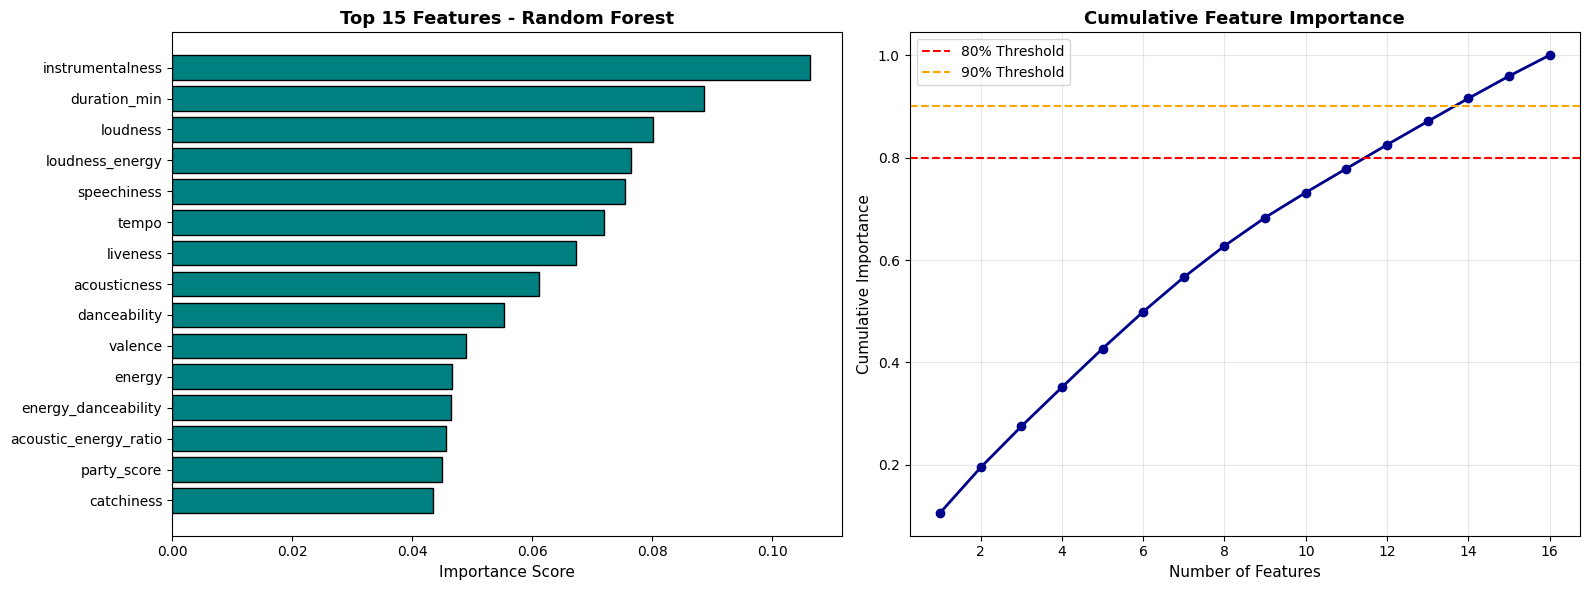


Number of features explaining 80% of importance: 11


In [34]:
best_model_name = comparison_df.loc[comparison_df['Test R²'].idxmax(), 'Model']
best_model = models_results[best_model_name]['model']

print(f"\nBest Model: {best_model_name}")
print(f"Test R²: {models_results[best_model_name]['test_r2']:.4f}")
print(f"Test RMSE: {models_results[best_model_name]['test_rmse']:.2f} popularity points")

if hasattr(best_model, 'feature_importances_'):
    feature_importance = pd.DataFrame({
        'Feature': feature_list,
        'Importance': best_model.feature_importances_
    }).sort_values('Importance', ascending=False)

    print("TOP 15 MOST IMPORTANT FEATURES FOR PREDICTING POPULARITY:")
    print(feature_importance.head(15).to_string(index=False))

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    top_features = feature_importance.head(15)
    axes[0].barh(range(len(top_features)), top_features['Importance'], color='teal', edgecolor='black')
    axes[0].set_yticks(range(len(top_features)))
    axes[0].set_yticklabels(top_features['Feature'])
    axes[0].set_xlabel('Importance Score', fontsize=11)
    axes[0].set_title(f'Top 15 Features - {best_model_name}', fontsize=13, fontweight='bold')
    axes[0].invert_yaxis()

    feature_importance['Cumulative'] = feature_importance['Importance'].cumsum()
    axes[1].plot(range(1, len(feature_importance) + 1),
                feature_importance['Cumulative'],
                marker='o', linewidth=2, markersize=6, color='darkblue')
    axes[1].axhline(y=0.8, color='red', linestyle='--', label='80% Threshold')
    axes[1].axhline(y=0.9, color='orange', linestyle='--', label='90% Threshold')
    axes[1].set_xlabel('Number of Features', fontsize=11)
    axes[1].set_ylabel('Cumulative Importance', fontsize=11)
    axes[1].set_title('Cumulative Feature Importance', fontsize=13, fontweight='bold')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    features_80 = (feature_importance['Cumulative'] <= 0.8).sum()
    print(f"\nNumber of features explaining 80% of importance: {features_80}")

elif hasattr(best_model, 'coef_'):
    coefficients = pd.DataFrame({
        'Feature': feature_list,
        'Coefficient': best_model.coef_
    }).sort_values('Coefficient', key=abs, ascending=False)


    print(coefficients.head(15).to_string(index=False))

    plt.figure(figsize=(12, 8))
    top_coefs = coefficients.head(15)
    colors = ['green' if x > 0 else 'red' for x in top_coefs['Coefficient']]
    plt.barh(range(len(top_coefs)), top_coefs['Coefficient'], color=colors, edgecolor='black')
    plt.yticks(range(len(top_coefs)), top_coefs['Feature'])
    plt.xlabel('Coefficient Value', fontsize=11)
    plt.title(f'Top 15 Feature Coefficients - {best_model_name}', fontsize=13, fontweight='bold')
    plt.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

